# Exploratory Data Analysis using for Car Price Prediction

Exploratory data analysis (EDA) is used by data scientists to analyze data sets and summarize their main characteristics, often employing data visualization methods. 

The main purpose of EDA is to help look at data before making any assumptions. It can help identify obvious errors, as well as better understand patterns within the data, detect outliers, find interesting relations among the variables.

Based on the results of EDA in real world, companies make business decisions to increase their profits.

reference: https://youtube.com/shorts/dfRi4KtdFSY?feature=share


Exploratory data analysis (EDA), Data Preprocessing, and Feature Engineering are all distinct terms, but they are comprised of a large number of subtasks that are overlapping in nature. At times, they are sometimes used in the same sentence as one another.

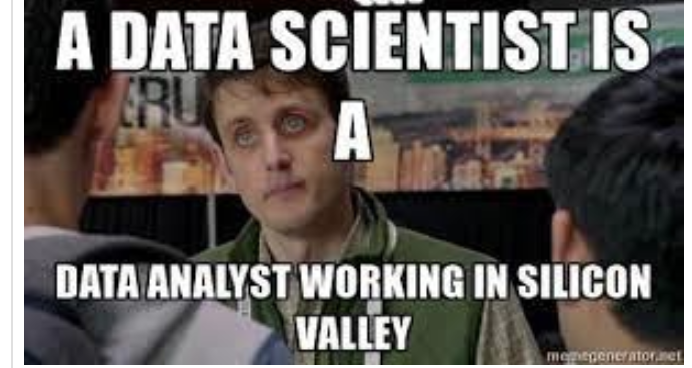


Exploratory data analysis is a way to better understand your data which helps in further Data preprocessing using feature engineering techniques. 


In [1]:
# importing essential libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

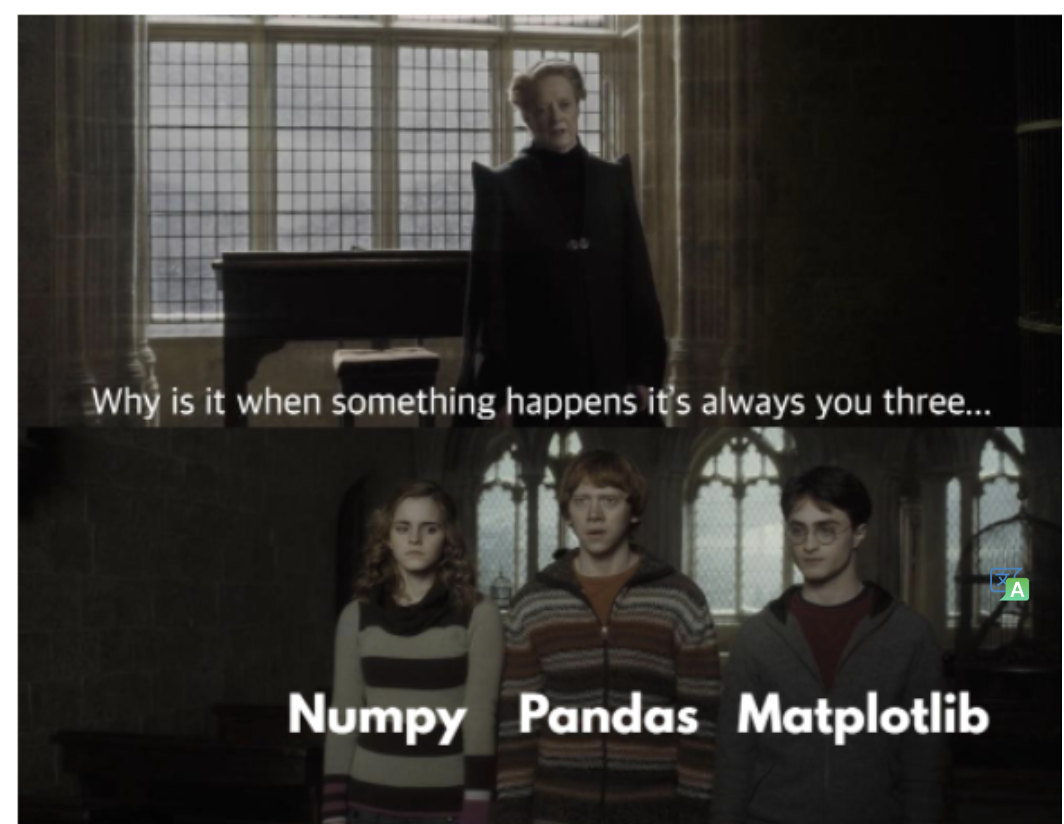

In [2]:
df = car = pd.read_csv("car_data.csv")

In [3]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


Check the datatypes
In Machine learning, it is very important to know appropriate datatypes of independent and dependent variable. as it provides the basis for selecting classification or regression models. Incorrect identification of data types leads to incorrect modeling which in turn leads to an incorrect solution.


In [4]:
# check datatypes of each column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB


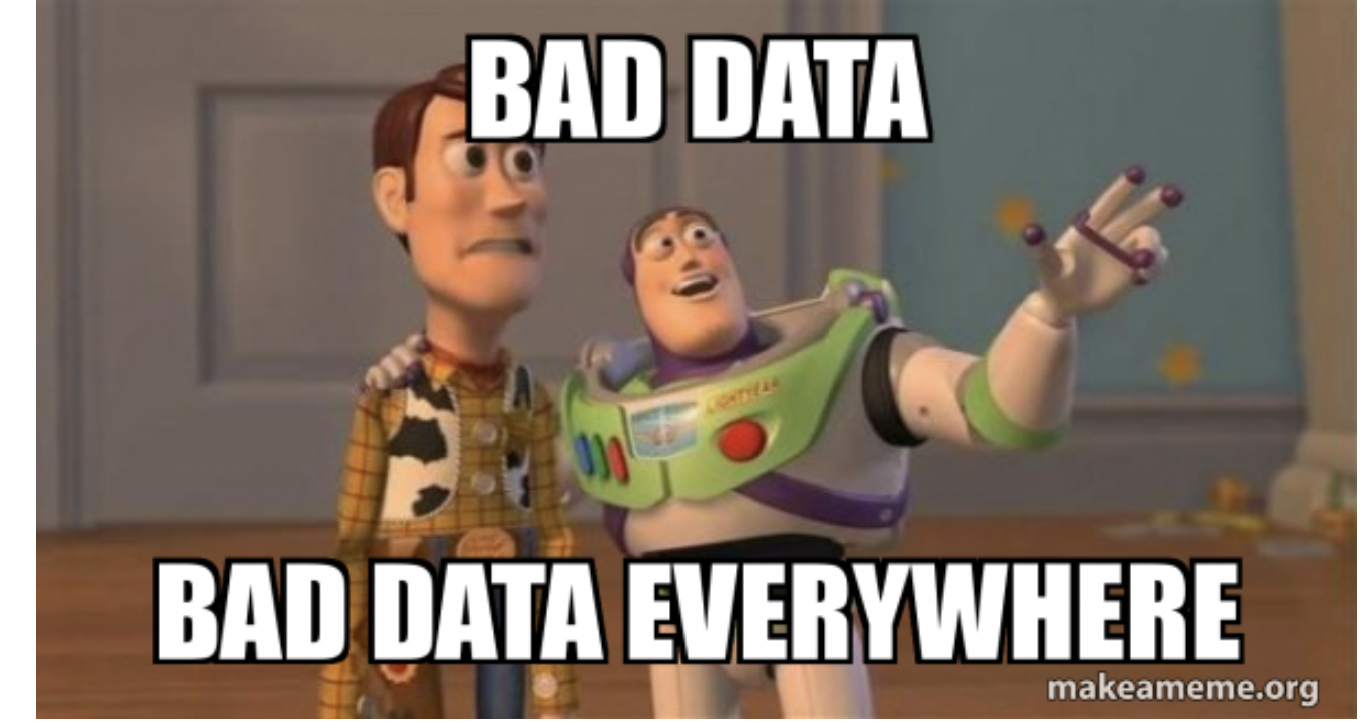

### Dropping Duplicate Rows
Datasets that contain duplicates may contaminate training data with the test data or vice versa, entries with missing values will lead models to misunderstand features and outliers will undermine the training process – leading your model to “learn” patterns that do not exist in reality.

In [5]:
# check for non-null values in each column
df.count()

name             8128
year             8128
selling_price    8128
km_driven        8128
fuel             8128
seller_type      8128
transmission     8128
owner            8128
mileage          7907
engine           7907
max_power        7913
torque           7906
seats            7907
dtype: int64

In [6]:
# drop duplicates
df = df.drop_duplicates()
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0


In [7]:
df.count()

name             6926
year             6926
selling_price    6926
km_driven        6926
fuel             6926
seller_type      6926
transmission     6926
owner            6926
mileage          6718
engine           6718
max_power        6721
torque           6717
seats            6718
dtype: int64

### Dropping missing values

In [8]:
# check for count of null values in each column
df.isnull().sum()

name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        205
torque           209
seats            208
dtype: int64

In [9]:
# drop missing values
df = df.dropna() 

In [10]:
# Make sure that missing values are removed
print(df.isnull().sum())

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           0
seats            0
dtype: int64


In [11]:
len(df)

6717

### Feature Splitting
Splitting features is a good way to make them useful in terms of machine learning. Most of the time the dataset contains string columns that violates tidy data principles. By extracting the utilizable parts of a column into new features: We enable machine learning algorithms to comprehend them.

In [12]:
# split mileage, engine and max_power to remove its units and keep only numerical values
df['mileage'] = df["mileage"].str.split(" ",expand=True)[0]
df['mileage'] = df['mileage'].astype('float64')
df['engine'] = df["engine"].str.split(" ",expand=True)[0]
df['engine'] = df['engine'].astype('float64')
df['max_power'] = df["max_power"].str.split(" ",expand=True)[0]
df['max_power'] = df['max_power'].astype('float64')

In [13]:
# feature splitting on brand names
df['brand'] = df['name'].str.split(" ",expand=True)[0] + ' ' + df['name'].str.split(" ",expand=True)[1]
df['brand'].value_counts()

brand
Maruti Swift         620
Maruti Alto          394
Hyundai i20          303
Maruti Wagon         245
Toyota Innova        188
                    ... 
Isuzu MU               1
Mercedes-Benz GLC      1
Volvo XC60             1
Volvo S90              1
Maruti S-Presso        1
Name: count, Length: 200, dtype: int64

The describe() function computes a summary of statistics related to the DataFrame numerical columns. This function gives the mean, std and IQR values.



In [14]:
# use describe function
df.describe()

,year,selling_price,km_driven,mileage,engine,max_power,seats
count,6717.000000,6.717000e+03,6.717000e+03,6717.000000,6717.000000,6717.000000,6717.000000
mean,2013.611136,5.263860e+05,7.339834e+04,19.466585,1430.985857,87.766100,5.434271
std,3.897402,5.235504e+05,5.870328e+04,4.048102,493.469198,31.724555,0.983805
min,1994.000000,2.999900e+04,1.000000e+00,0.000000,624.000000,32.800000,2.000000
25%,2011.000000,2.500000e+05,3.800000e+04,16.800000,1197.000000,67.100000,5.000000
50%,2014.000000,4.200000e+05,6.820300e+04,19.440000,1248.000000,81.830000,5.000000
75%,2017.000000,6.500000e+05,1.000000e+05,22.500000,1498.000000,100.000000,5.000000
max,2020.000000,1.000000e+07,2.360457e+06,42.000000,3604.000000,400.000000,14.000000


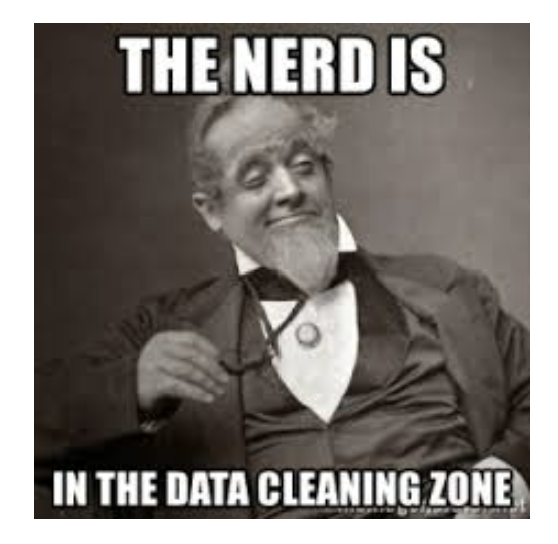

### Feature Creation
Sometimes we need to create new features so that our data makes more sense and it becomes easy for model to learn and intepret.

Example, we have a column 'year' which represents in which year, the car was bought. But, if we create a new feature that shows how old the car is, it makes more sense then to use it to decide price of a car for our model.  

In [15]:
# create a new feature which shows how old the car is
current_year = 2026
df['old'] = current_year - df['year']
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,brand,old
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,Maruti Swift,12
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,Skoda Rapid,12
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,Honda City,20
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,Hyundai i20,16
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti Swift,19


# Dropping irrelevant columns
Useless columns can dangerously mislead our model that's why it is important to drop them.

In [16]:
# rename the columns as shown above 
renamed_columns = {'selling_price':'price','km_driven':'kms','seller_type':'seller','max_power':'power'}
df = df.rename(columns = renamed_columns)
df.head()

,name,year,price,kms,fuel,seller,transmission,owner,mileage,engine,power,torque,seats,brand,old
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,Maruti Swift,12
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,Skoda Rapid,12
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,Honda City,20
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,Hyundai i20,16
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti Swift,19


### Handling Outliers

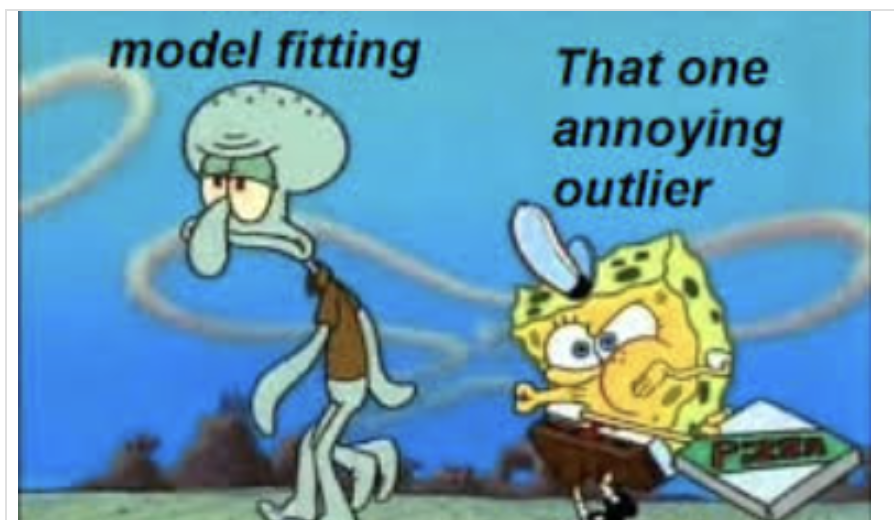

In [17]:
# show df columns with numerical datatypes
df.loc[:, df.dtypes != object]

,name,year,price,kms,fuel,seller,transmission,owner,mileage,engine,power,torque,seats,brand,old
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190Nm@ 2000rpm,5.0,Maruti Swift,12
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250Nm@ 1500-2500rpm,5.0,Skoda Rapid,12
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,"12.7@ 2,700(kgm@ rpm)",5.0,Honda City,20
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,22.4 kgm at 1750-2750rpm,5.0,Hyundai i20,16
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,"11.5@ 4,500(kgm@ rpm)",5.0,Maruti Swift,19
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8121,Maruti Wagon R VXI BS IV with ABS,2013,260000,50000,Petrol,Individual,Manual,Second Owner,18.90,998.0,67.10,90Nm@ 3500rpm,5.0,Maruti Wagon,13
8122,Hyundai i20 Magna 1.4 CRDi,2014,475000,80000,Diesel,Individual,Manual,Second Owner,22.54,1396.0,88.73,219.7Nm@ 1500-2750rpm,5.0,Hyundai i20,12
8123,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.50,1197.0,82.85,113.7Nm@ 4000rpm,5.0,Hyundai i20,13
8124,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.80,1493.0,110.00,"24@ 1,900-2,750(kgm@ rpm)",5.0,Hyundai Verna,19


### Boxplot for Outliers
- A boxplot is a graph that gives you a good indication of how the values in the data are spread out. 
- They are generally used to visualise outliers in the data.


#### boxplot - price

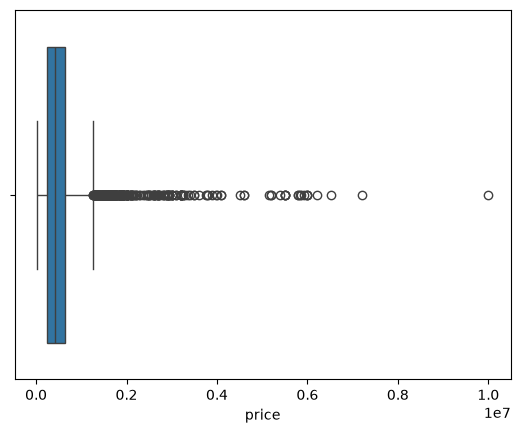

In [18]:
# show the boxplot for price column to look at outliers 
sns.boxplot(x=df['price'])
plt.show()

As it is our target column, and outliers in target columns are sometimes important to understand the trend, that's why we are going to keep outliers here, but for other independent columns, we'll remove the outliers.

#### old - handling outliers
Now we will apply handling outlier's for "old" column using Capping the outliers method that we learnt in feature engineering module.

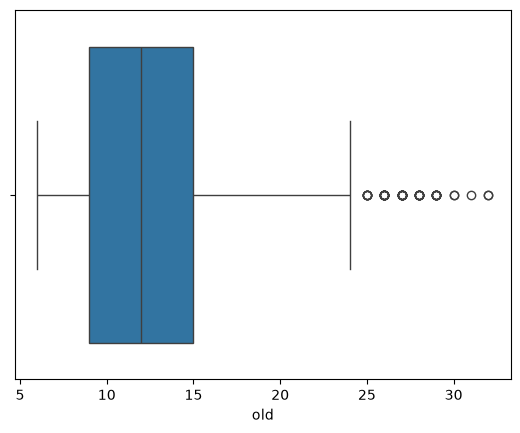

In [19]:
# show the boxplot for price column to look at outliers 
sns.boxplot(x=df['old'])
plt.show()

In [20]:
# set the upper limit and lower limit and apply it for outliers
upper_lim = df['old'].quantile(0.95)
lower_lim = df['old'].quantile(0.05)
df.loc[(df['old'] > upper_lim),'old'] = upper_lim
df.loc[(df['old'] < lower_lim),'old'] = lower_lim

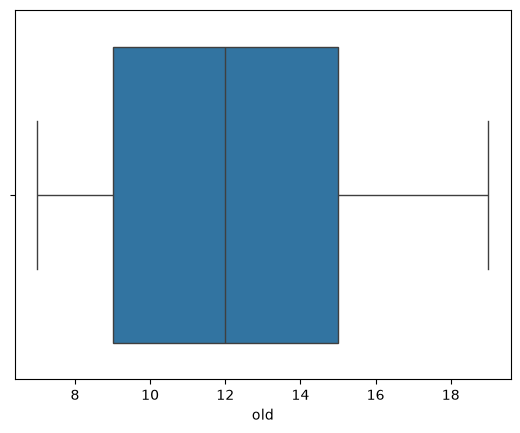

In [21]:
sns.boxplot(x=df['old'])
plt.show()

#### power - handling outliers
Repeat the same method for "power" column.

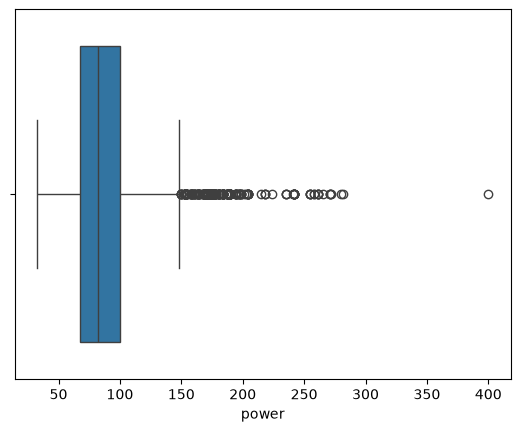

In [22]:
# show the boxplot for "power" column
sns.boxplot(x=df['power'])
plt.show()

In [23]:
# Capping the outliers
upper_lim = df['power'].quantile(0.95)
lower_lim = df['power'].quantile(0.05)
df.loc[(df['power'] > upper_lim),'power'] = upper_lim
df.loc[(df['power'] < lower_lim),'power'] = lower_lim

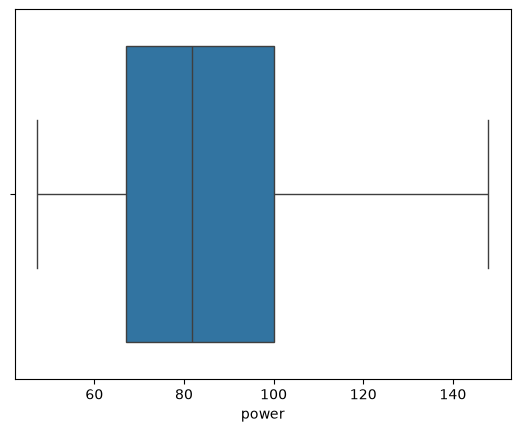

In [24]:
# show the boxplot and observe the difference
sns.boxplot(x=df['power'])
plt.show()

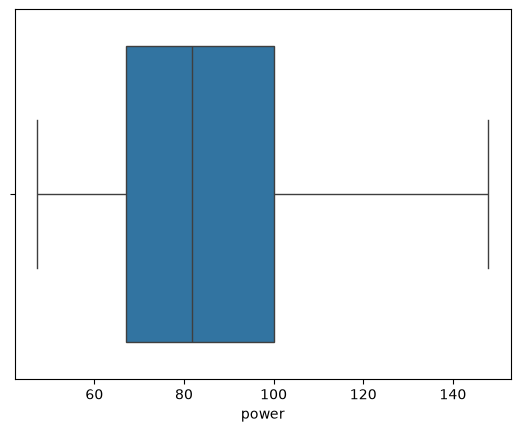

In [25]:
df2 = sns.boxplot(x=df['power'])

In [26]:
df['power'].head()

0     74.00
1    103.52
2     78.00
3     90.00
4     88.20
Name: power, dtype: float64

In [27]:
df2 = df['power'].head()

In [28]:
df2.to_csv('data.csv')

In [29]:
df2

0     74.00
1    103.52
2     78.00
3     90.00
4     88.20
Name: power, dtype: float64

#### kms - handling outliers
Now we will apply handling outlier's for "kms" column using Standard deviation based method that we learnt in feature engineering module.

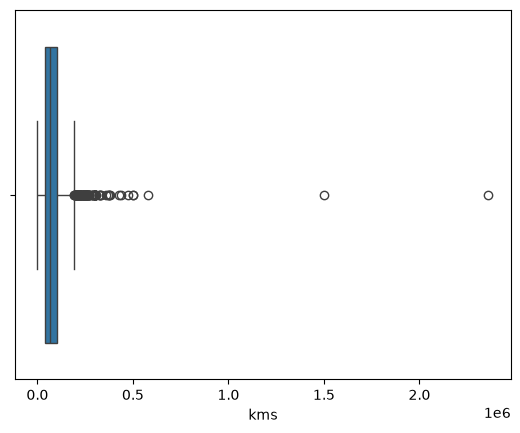

In [30]:
# show the boxplot for 'kms' column
sns.boxplot(x=df['kms'])
plt.show()

In [31]:
# set the upper limit and lower limit for removing the outliers
factor = 3
upper_lim = df['kms'].mean() + df['kms'].std() * factor
lower_lim = df['kms'].mean() - df['kms'].std() * factor

In [32]:
# apply that change on new data
df = df[(df['kms'] < upper_lim) & (df['kms'] > lower_lim)]

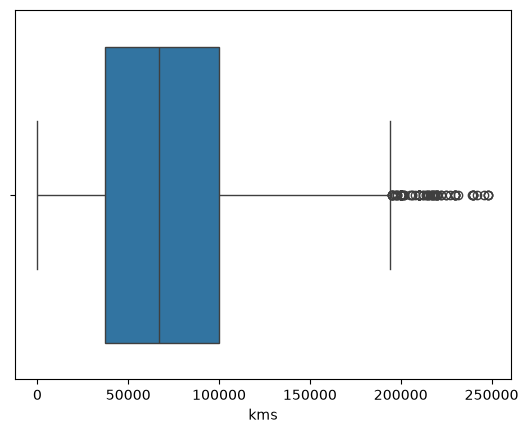

In [33]:
# show the boxplot and observe the change
sns.boxplot(x=df['kms'])
plt.show()

In this module we'll learn new Handling Outlier's Method:

### Inter Quantile Range(IQR)
The interquartile range defines the difference between the third and the first quartile. Quartiles are the partitioned values that divide the whole series into 4 equal parts. So, there are 3 quartiles. First Quartile is denoted by Q1 known as the lower quartile, the second Quartile is denoted by Q2 and the third Quartile is denoted by Q3 known as the upper quartile. Therefore, the interquartile range is equal to the upper quartile minus lower quartile.


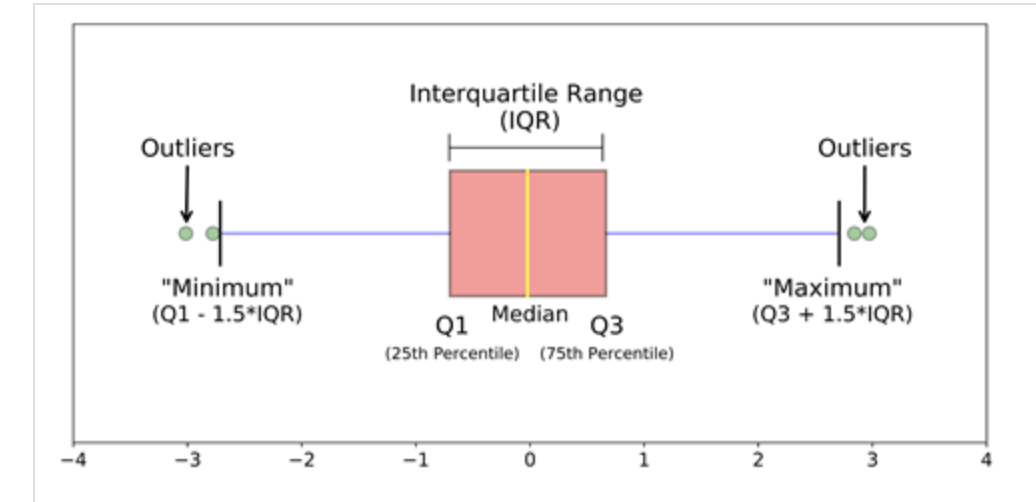

Steps to eliminate outliers:
- Sort the dataset in ascending order
- calculate the 1st and 3rd quartiles(Q1, Q3)
- compute IQR=Q3-Q1
- give a suitable threshold and compute lower bound = (Q1–1.5\*IQR), upper bound = (Q3+1.5\*IQR)
- eliminate those above upper bound and those below lower bound

#### engine - handling outliers

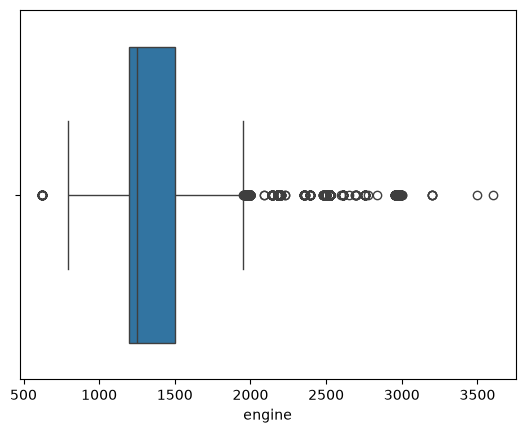

In [34]:
# show the boxplot for "engine" column
sns.boxplot(x=df['engine'])
plt.show()

In [35]:
# set q1 and q3 values, determine IQR, set upper bound and lower bound and apply it on our DataFrame df for 'engine' column
q1 = df['engine'].quantile(0.25)
q3 = df['engine'].quantile(0.75)
IQR = q3 - q1 
lower_bound = q1-(1.5*IQR)
upper_bound = q3+(1.5*IQR)
df = df[~((df['engine'] < lower_bound) | (df['engine'] > upper_bound))]

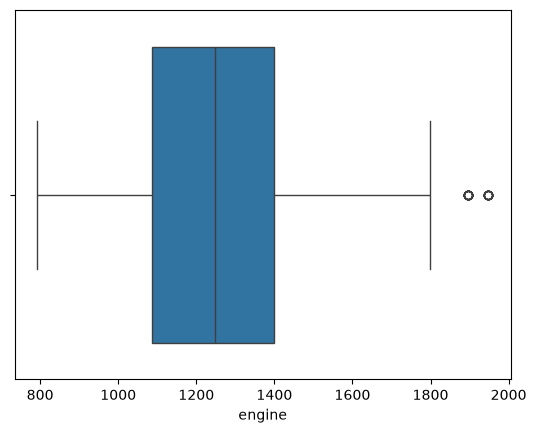

In [36]:
# show the boxplot for 'engine' column and observe the difference
sns.boxplot(x=df['engine'])
plt.show()

#### mileage - handling outliers
We will repeat same method for mileage column now.

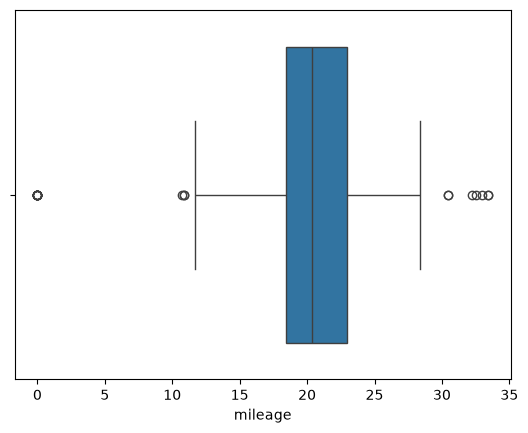

In [37]:
# show the boxplot for 'mileage' column
sns.boxplot(x=df['mileage'])
plt.show()

In [38]:
# set q1 and q3 values, determine IQR, set upper bound and lower bound and apply it on our DataFrame df for 'mileage' column
q1 = df['mileage'].quantile(0.25)
q3 = df['mileage'].quantile(0.75)
IQR = q3 - q1 
lower_bound = q1-(1.5*IQR)
upper_bound = q3+(1.5*IQR)
df = df[~((df['mileage'] < lower_bound) | (df['mileage'] > upper_bound))]

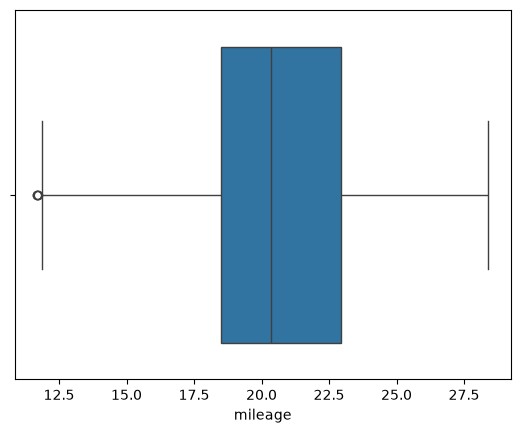

In [39]:
# show the boxplot for 'mileage' column
sns.boxplot(x=df['mileage'])
plt.show()

### DataFrame Index
Indexing in pandas means simply selecting particular rows and columns of data from a DataFrame. We try to keep it as much uniform and as much easily accessible for us to use. That's why it is important to clean irregular DataFrame indexes.

In [40]:
# check the index of dataframe
df.index

Index([   0,    1,    2,    3,    4,    5,    6,    7,    8,    9,
       ...
       8115, 8116, 8118, 8119, 8120, 8121, 8122, 8123, 8124, 8125],
      dtype='int64', length=5477)

In [41]:
print(df.index[1])

1


As you can see, the dataframe index is irregular above, ranges from 0 to 8125, yet has length of 5477. That's why it is important to correct our dataframe index. 

In [42]:
# reset the index 
df.reset_index(inplace=True,drop=True)
# reset_index will delete the index instead of inserting it back into the columns of the DataFrame
# if we don't do drop=True, then it will create a column in our df which will contain the old index values
df.tail()

,name,year,price,kms,fuel,seller,transmission,owner,mileage,engine,power,torque,seats,brand,old
5472,Maruti Wagon R VXI BS IV with ABS,2013,260000,50000,Petrol,Individual,Manual,Second Owner,18.90,998.0,67.10,90Nm@ 3500rpm,5.0,Maruti Wagon,13
5473,Hyundai i20 Magna 1.4 CRDi,2014,475000,80000,Diesel,Individual,Manual,Second Owner,22.54,1396.0,88.73,219.7Nm@ 1500-2750rpm,5.0,Hyundai i20,12
5474,Hyundai i20 Magna,2013,320000,110000,Petrol,Individual,Manual,First Owner,18.50,1197.0,82.85,113.7Nm@ 4000rpm,5.0,Hyundai i20,13
5475,Hyundai Verna CRDi SX,2007,135000,119000,Diesel,Individual,Manual,Fourth & Above Owner,16.80,1493.0,110.00,"24@ 1,900-2,750(kgm@ rpm)",5.0,Hyundai Verna,19
5476,Maruti Swift Dzire ZDi,2009,382000,120000,Diesel,Individual,Manual,First Owner,19.30,1248.0,73.90,190Nm@ 2000rpm,5.0,Maruti Swift,17


In [43]:
# check the index of dataframe
df.index

RangeIndex(start=0, stop=5477, step=1)

## Data Visualization

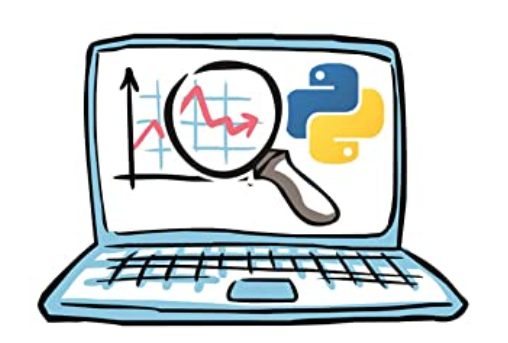

Data visualization is the graphical representation of information and data. By using visual elements like charts, graphs, and maps, data visualization tools provide an accessible way to see and understand trends, outliers, and patterns in data. It helps data scientists perform complex data analysis, recognizing patterns, and understanding datasets.




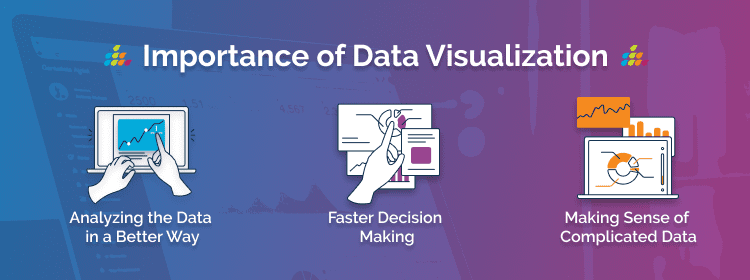

### Useful packages for visualizations in python
#### Matplotlib
Matplotlib is a visualization library in Python for 2D plots of arrays. It is written in Python and makes use of the NumPy library. Matplotlib comes with a wide variety of plots like line, bar, scatter, histogram, etc. which can help us, deep-dive, into understanding trends, patterns, correlations. 

#### Seaborn
Seaborn is a dataset-oriented library for making statistical representations in Python. It is developed on top of matplotlib and to create different visualizations. It is integrated with pandas data structures.

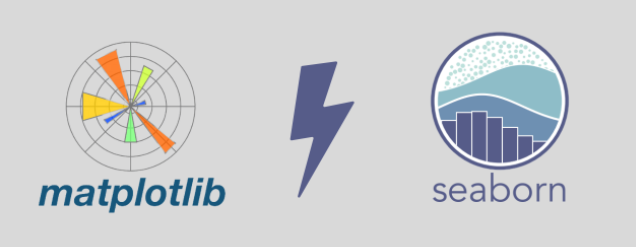

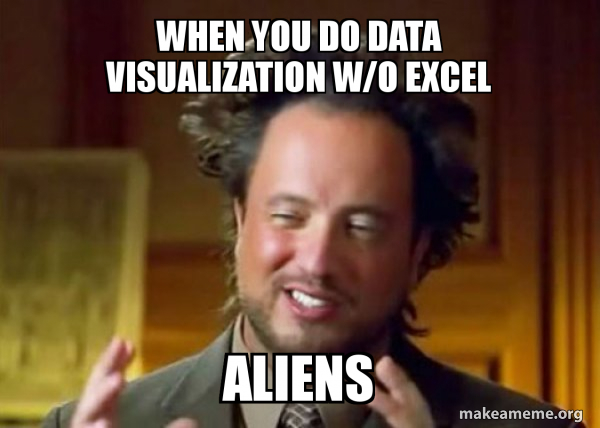

## Visualizing Univariate Distributions
- Univariate data visualization plots help us to analyse and understand the properties of a particular column(variable) in our dataset. 
- Univariate analysis is basically the simplest form to analyze data. Uni means one and this means that the data has only one kind of variable. 
- The major reason for univariate analysis is to use the data to describe. The analysis will take data, summarise it, and then find some pattern in the data. 


C:\Users\HP POWER\AppData\Local\Temp\ipykernel_15380\3079001501.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['power'])


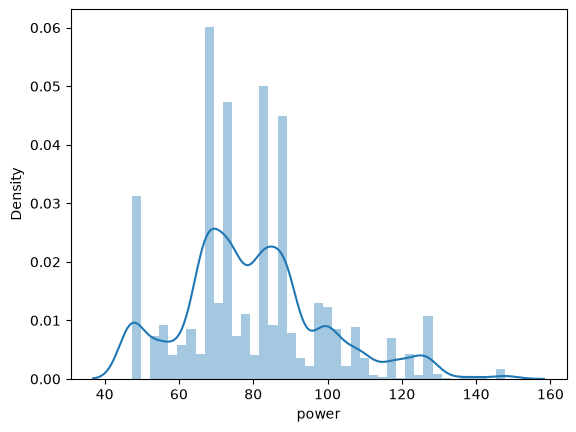

In [44]:
# plot a histogram for "power" col
sns.distplot(df['power'])
plt.show()

In [45]:
# make a list of all the columns which contain numerical values
num_cols = list(df.loc[:, df.dtypes != object].columns)
num_cols

['name',
 'year',
 'price',
 'kms',
 'fuel',
 'seller',
 'transmission',
 'owner',
 'mileage',
 'engine',
 'power',
 'torque',
 'seats',
 'brand',
 'old']

C:\Users\HP POWER\AppData\Local\Temp\ipykernel_15380\2091301914.py:8: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df[i])


ValueError: could not convert string to float: 'Maruti Swift Dzire VDI'

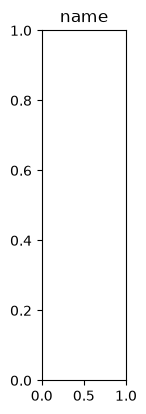

In [46]:
# plot the coLumns present in num_coLs together using subplot Of dimention (2,3)
c=0
plt.figure(figsize=(5,10))
for i in num_cols:
    c=c+1
    plt.subplot(2, 4, c)
    plt.title(i)
    sns.distplot(df[i])
plt.show()    

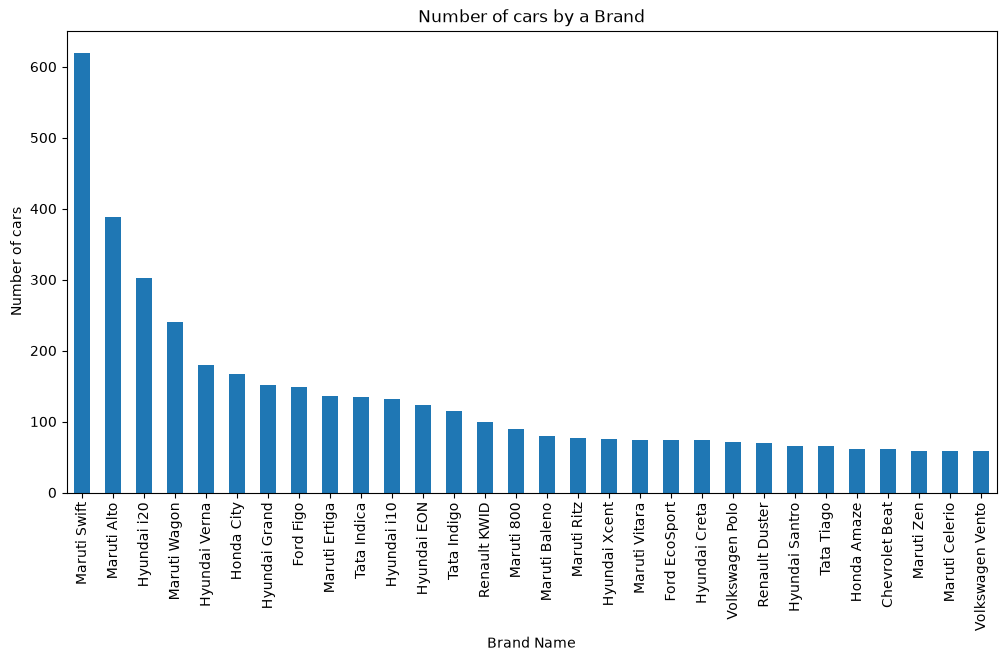

In [47]:
# Plot a bar graph for number of cars vs each brand
plt.figure(figsize = (12,8))
df.brand.value_counts().nlargest(30).plot(kind='bar',figsize=(12,6))
plt.title('Number of cars by a Brand')
plt.ylabel('Number of cars')
plt.xlabel('Brand Name');

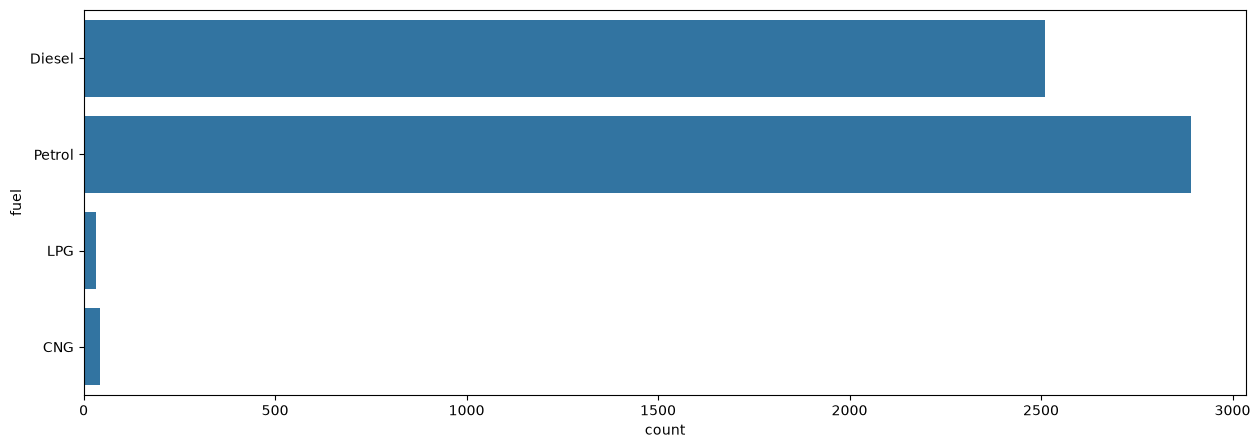

In [48]:
plt.figure(figsize=(15,5))
sns.countplot(df['fuel'])
plt.show()

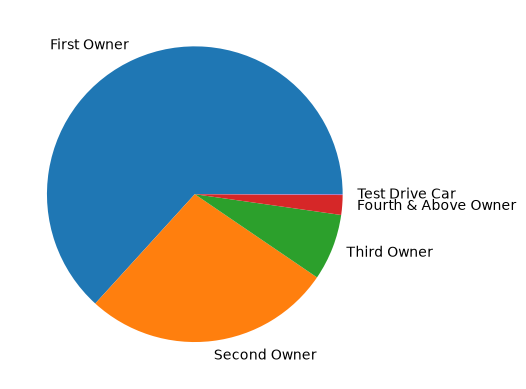

In [49]:
# plot the pie chart of seller categories
df.owner.value_counts(normalize=True).plot.pie()
plt.show()

# Visualizing Bivariate Distributions
• Bivariate analysis means the analysis of bivariate data, bi means two, so analysis of two
variables.

• It is one of the simplest forms Of statistical analysis, where two variables are observed
against each Other.

• Analysing two variables(or columns) can help us determine the relationships between
them.

1. Scatter Plot

• A scatter plot uses dots to represent values for two different numeric variables(or
columns).

The position Of each dot on the horizontal and vertical axis indicates values for an
individual data point.

• One column is on horizontal axis and another on vertical axis (x and y axis) and points
are plot accorinding to that and this is how scatter plots are used to observe
relationships between these 2 variables.

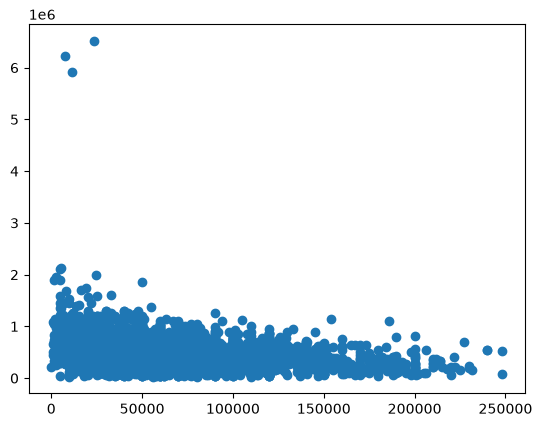

In [50]:
# plot the scatter plot of price and kms variable in data
plt.scatter(df.kms,df.price)
plt.show()

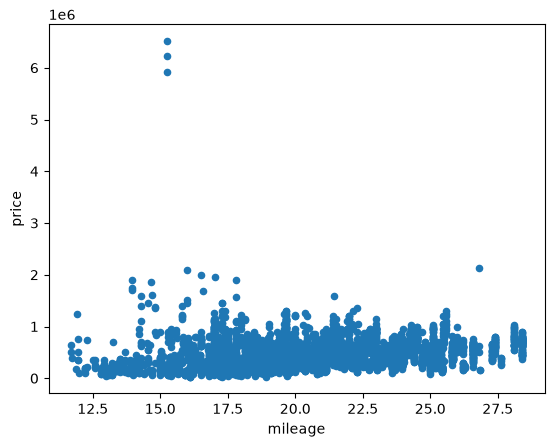

In [51]:
# plot the scatter plot of price and  variable in data
df.plot.scatter(x="mileage",y="price")
plt.show()

2. Line Plot

• A line plot makes a line to represent values for two different numeric variables(or
columns).

• One column is on horizontal axis and another on vertical axis (x and y axis) and points
are plot accorinding to this axis.

After this, dots are connected to form a line, which will show relationships between these 2 variables.

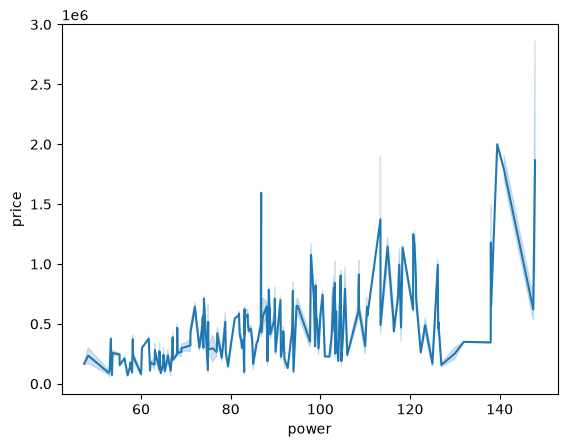

In [52]:
# show a lineplot for "price" vs "power"
sns.lineplot(x='power',y='price',data = df)
plt.show()

# 3. Box Plot


We use this plots earlier for detecting outliers. That was an example of univariate analysis,
but we will see now how we can use it for bivariate analysis.

• Boxplot is a chart that is used to visualize how a given data (variable) is distributed using
quartiles.

• It makes comparing characteristics of data between categories very easy.

• We can compare the medians, spread of data, outliers and skewness for different
categories injust one figure.

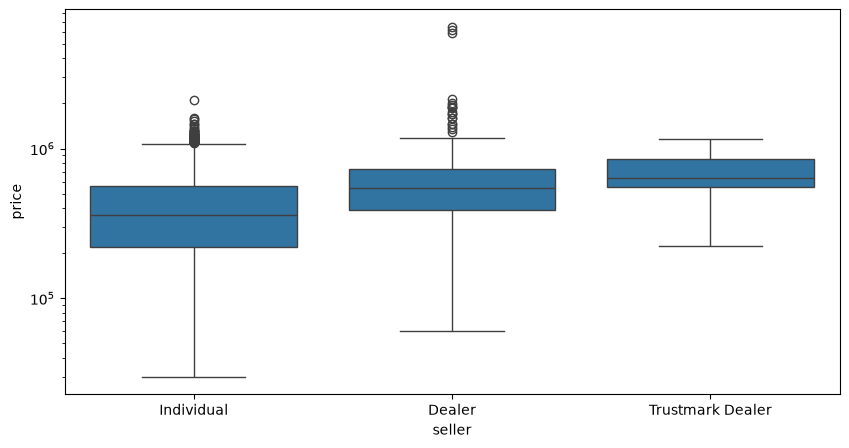

In [53]:
# boxplot of 'price' vs 'seller'
plt.figure(figsize=(10,5))
sns.boxplot(x='seller', y='price', data=df)
plt.yscale('log')
plt.show()

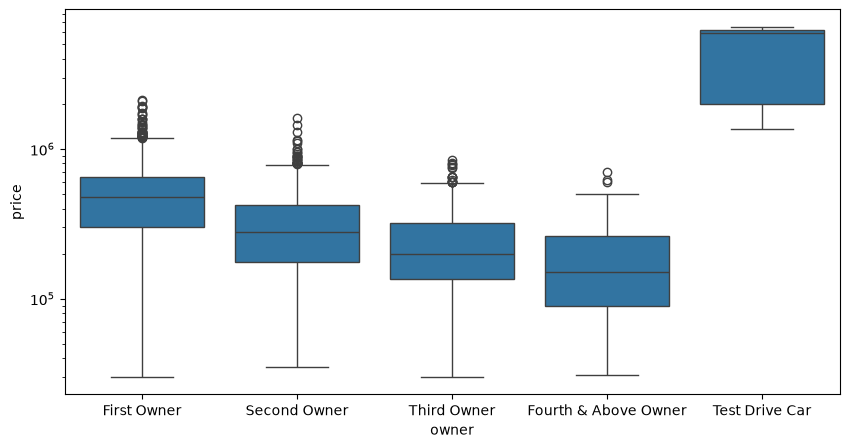

In [54]:
# boxplot of 'price' vs 'seller'
plt.figure(figsize=(10,5))
sns.boxplot(x='owner', y='price', data=df)
plt.yscale('log')
plt.show()

# 4. Violin Plot


A violin plot is more informative than a plain box plot. While a box plot Only shows summary
statistics such as mean/median and interquartile ranges, the violin plot shows the full
distribution of the data.

• A violin plot is a hybrid of a box plot and a kernel density plot, which shows
distributions of numeric data for one or more groups using density curves,

 It shows the distribution Of quantitative data across several levels Of one (Or more)
categorical variables such that those distributions can be compared.

Violin Plot = Box Plot + Distribution/Density Plot

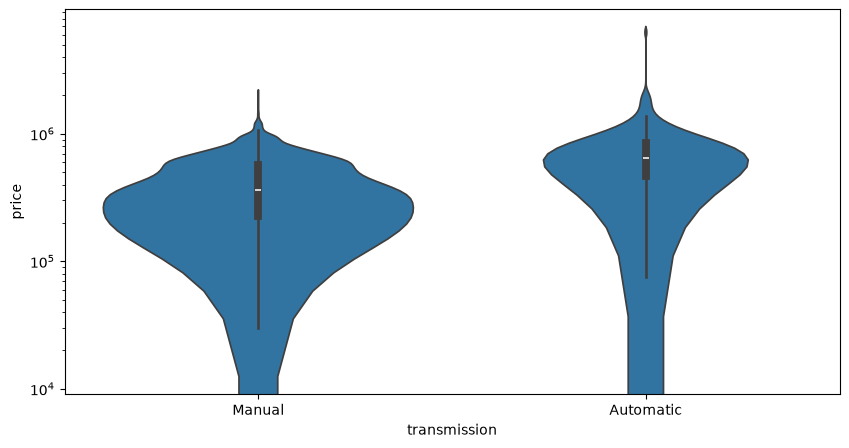

In [55]:
plt.figure(figsize=(10,5))
sns.violinplot(x='transmission', y='price', data=df)
plt.yscale('log')
plt.show()

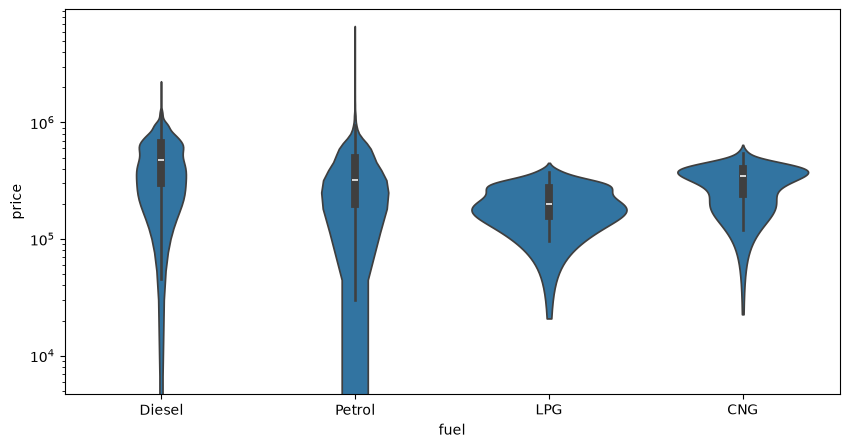

In [56]:
plt.figure(figsize=(10,5))
sns.violinplot(x='fuel', y='price', data=df)
plt.yscale('log')
plt.show()

# 5. Joint Plot

• Jointplot can be used to quickly visualize and analyze the relationship between two
variables and describe their individual distributions on the same plot

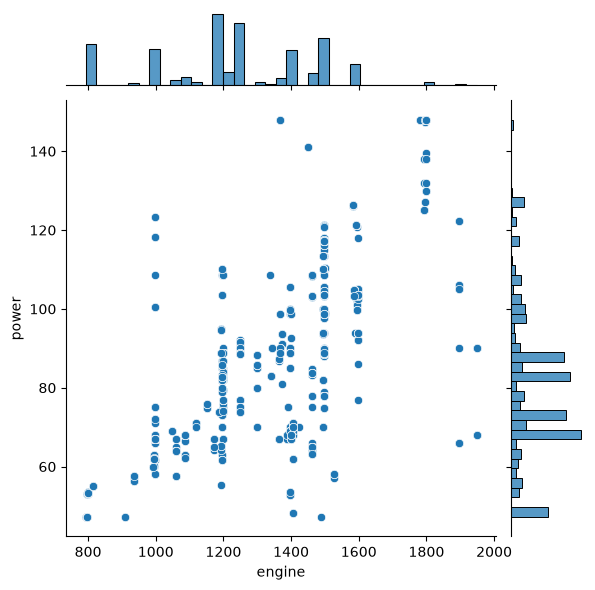

In [57]:
# joint plot of engine and power
sns.jointplot(data =df, x='engine',y='power')
plt.show()

Another way of visualizing a bivariate relationship using joint plot, in particular when we
have a large amount Of data, is the hexplot.

A hexplot splits the plotting window into several
hexbins and then the number Of observations which fall into each bin corresponds with a
color to indicate density.

A darker color hexbin means that there are more observations, Or
more density, within that region.

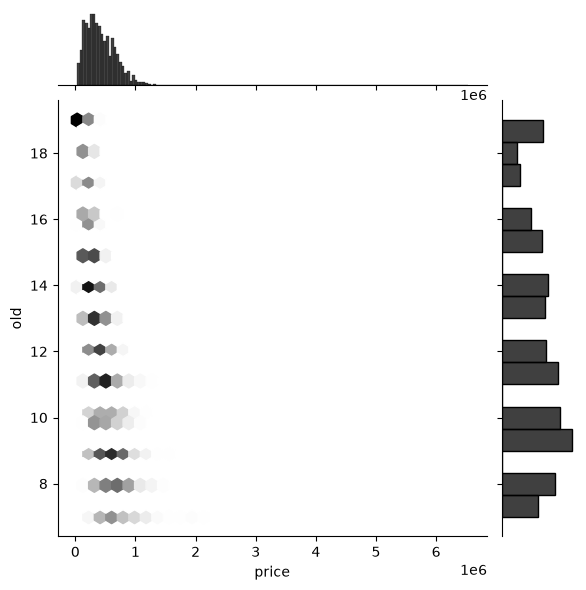

In [58]:
# joint plot Of price and Old
sns.jointplot(data =df, x='price',y='old',kind="hex", color="k")
plt.show()

# Visualizing Multivariate Distributions

• Multivariate analysis is where we analyze multiple data dimensions or attributes (2 or
more).

• Multivariate analysis not only involves just checking Out distributions but also potential
relationships, patterns and correlations amongst these attributes.

• You can also leverage inferential statistics and hypothesis testing if necessary based on
the problem to be solved at hand to check Out statistical significance for different
attributes, groups and so on.

# 1. Pair Plot

• A pairplot plot a pairwise relationships in a dataset.

A pairs plot allows us to see both distribution Of single variables and relationships
between two variables.

The pairplot function creates a grid of Axes such that each variable in data will by
shared in the y-axis across a single row and in the x-axis across a single column

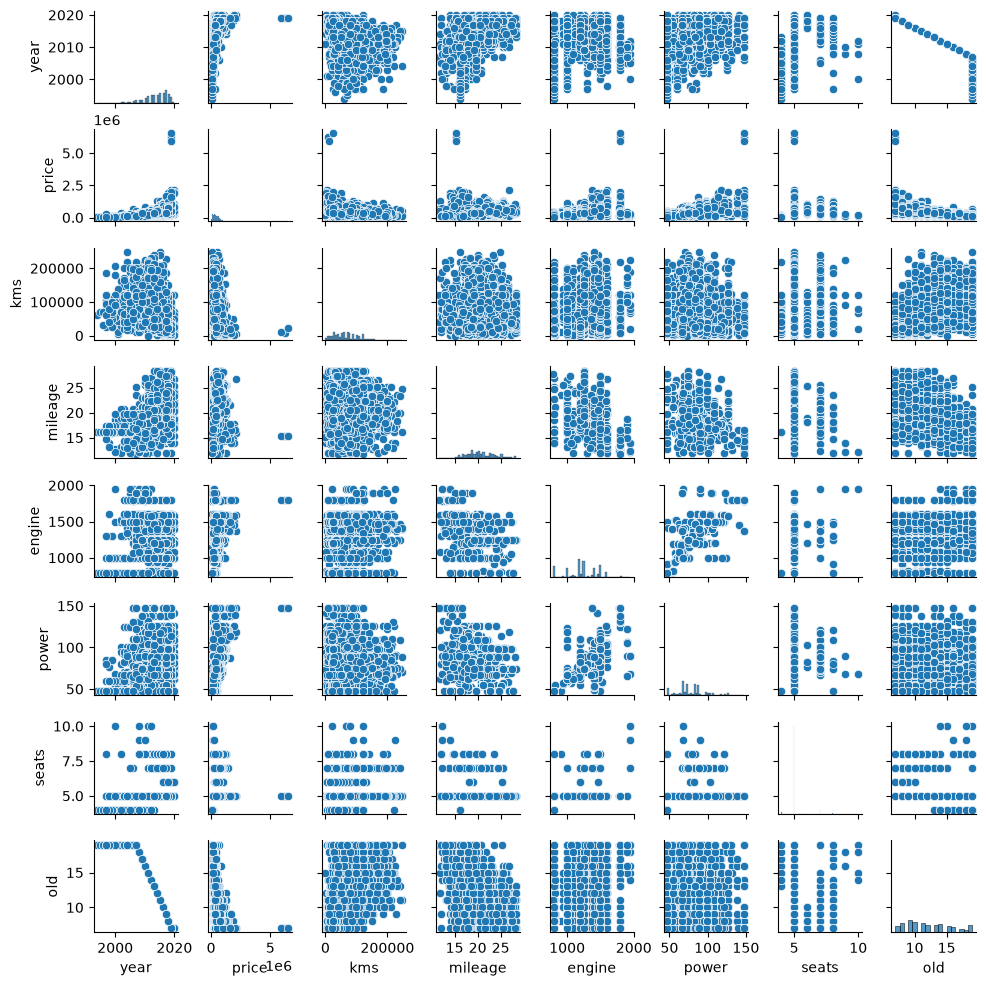

In [65]:
# plot the pairpLot for data df
sns.pairplot(df,height=1.25)
plt.show()

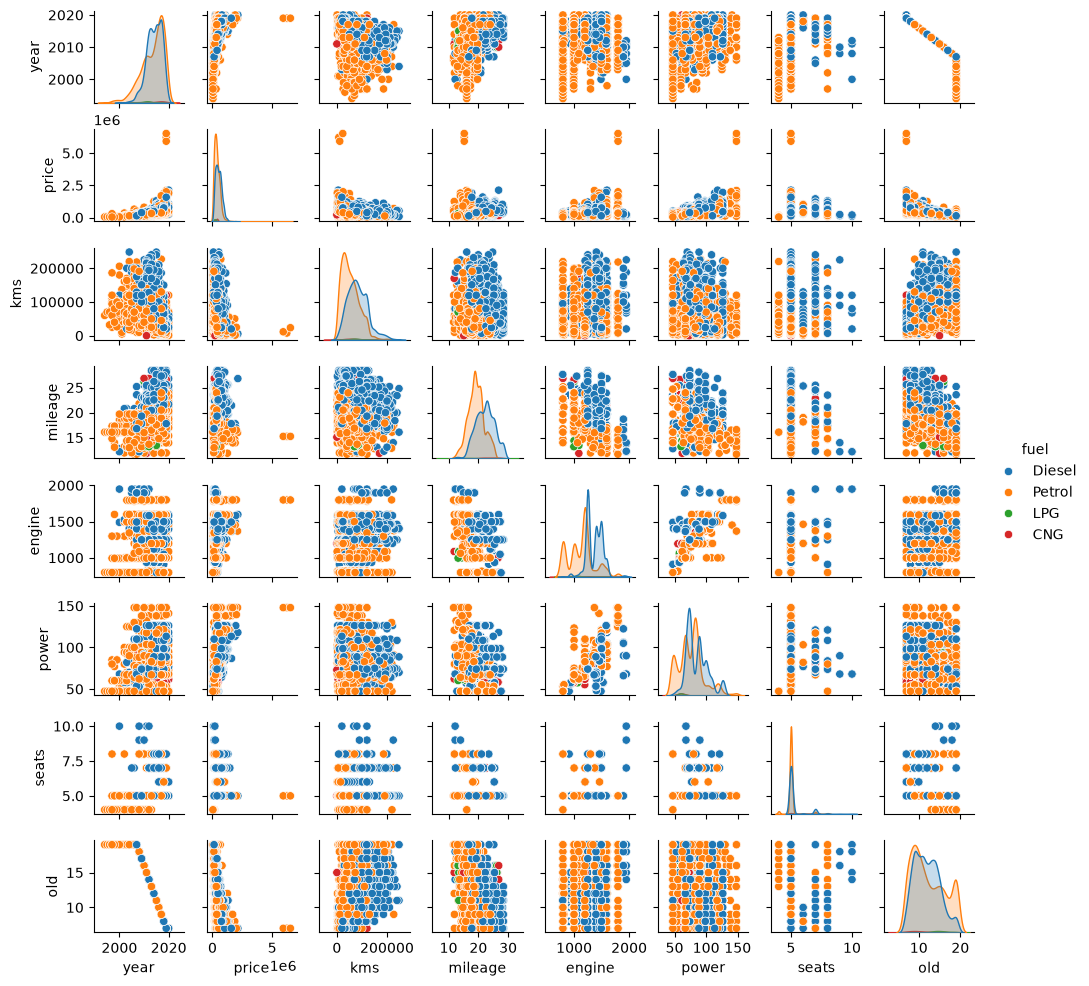

In [61]:
# plot a pairpLot for data df "'fth hue transmission
sns.pairplot(df,hue='fuel',height=1.25)
plt.show()

# 2. Multivariate Scatter Plot
• This kind of scatterplot uses three visual variables(2 numeric and 1 categorical).

• The horizontal position (x-value) and the vertical position (y-value) tracks values for two
different numeric variables(or columns).

• And the color (the hue parameter) tracks which Of the categories from categorial
column the point represents is in.

• Similar to scatter plot, we can observe relationship between 2 columns but now, with
respect to each category.

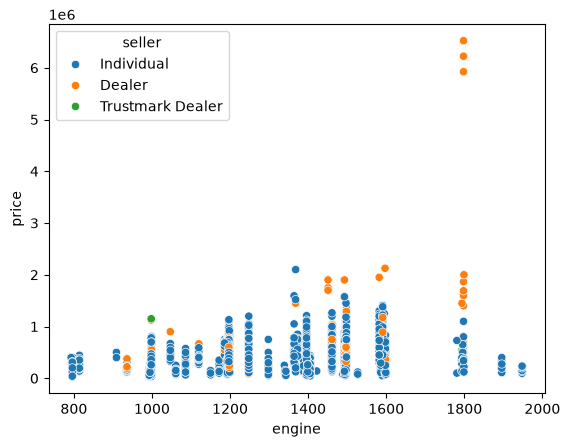

In [66]:
# multivariate scatterplot using seaborn
sns.scatterplot(x='engine', y='price', hue='seller', data=df)
plt.show()

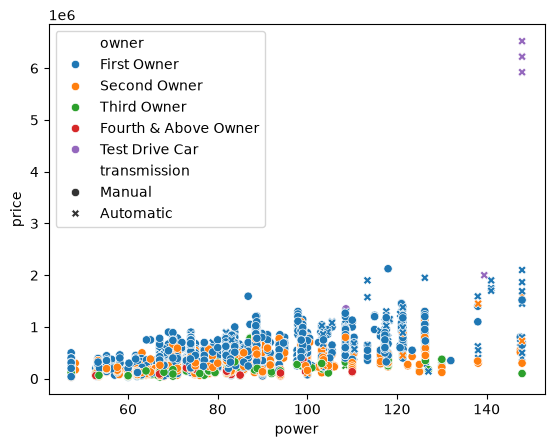

In [68]:
# multivariate scatterplot using seaborn
sns.scatterplot(x='power', y='price', hue='owner', style='transmission', data=df)
plt.show()

# 3. Multivariate Bar Plot

• This kind of barplot uses three visual variables(l numeric and 2 categorical).

• This works similar to Bar graph, but in addition, the previous variable is segmented to
observe relationship with respect to another variable used as a hue.

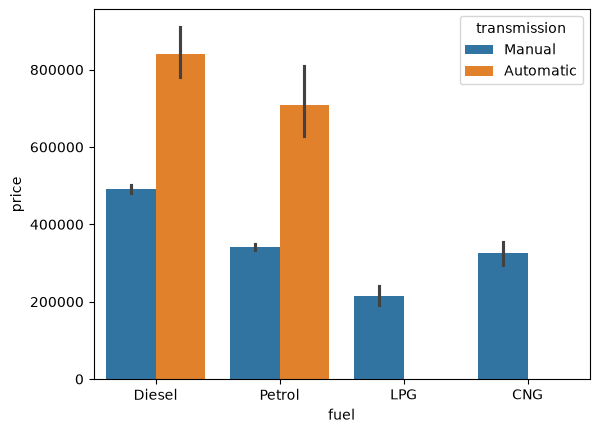

In [70]:
# show barplot for "price" vs "fuel" and show them separately for each transmission
sns.barplot(x='fuel', y='price', hue='transmission', data=df)
# hue means a color or a shade so, here, hue="column name" means provide datapoints
plt.show()

# 4. Heatmaps

• A heatmap is a graphical representation of data that uses a system of color-coding to
represent different values.

• A correlation heatmap is a graphical representation of a correlation matrix representing
the correlation between different variables. The value of correlation can take any value
from -1 to 1.

• The color of the cell is proportional to the value representing the relation between those
two variables. This means that when you look at your heat map, you can quickly see
which variables are highly correlated and which aren't.

In [74]:
# find the correlation of features of the data
train_corr = df.corr(numeric_only=True)
train_corr

,year,price,kms,mileage,engine,power,seats,old
year,1.000000,0.626021,-0.469469,0.436823,0.078856,0.236448,0.169502,-0.973337
price,0.626021,1.000000,-0.313294,0.213228,0.391130,0.560715,0.156155,-0.646738
kms,-0.469469,-0.313294,1.000000,-0.083047,0.214608,0.003496,0.025864,0.506775
mileage,0.436823,0.213228,-0.083047,1.000000,-0.139579,-0.136386,-0.078308,-0.432364
engine,0.078856,0.391130,0.214608,-0.139579,1.000000,0.806896,0.152518,-0.045036
power,0.236448,0.560715,0.003496,-0.136386,0.806896,1.000000,0.104945,-0.218049
seats,0.169502,0.156155,0.025864,-0.078308,0.152518,0.104945,1.000000,-0.155505
old,-0.973337,-0.646738,0.506775,-0.432364,-0.045036,-0.218049,-0.155505,1.000000


Text(0.5, 1.0, 'Simple Heatmap')

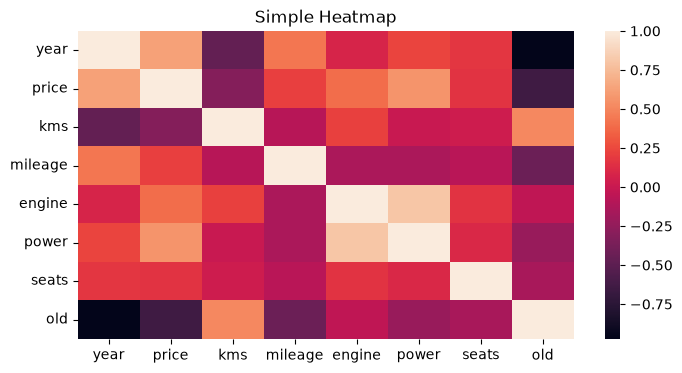

In [75]:
# plot a simple heatmap using the correlations found above
fig,ax = plt.subplots(figsize=(8,4))
sns.heatmap(train_corr)
ax.set_title('Simple Heatmap')

Text(0.5, 1.0, 'cmap=Accent')

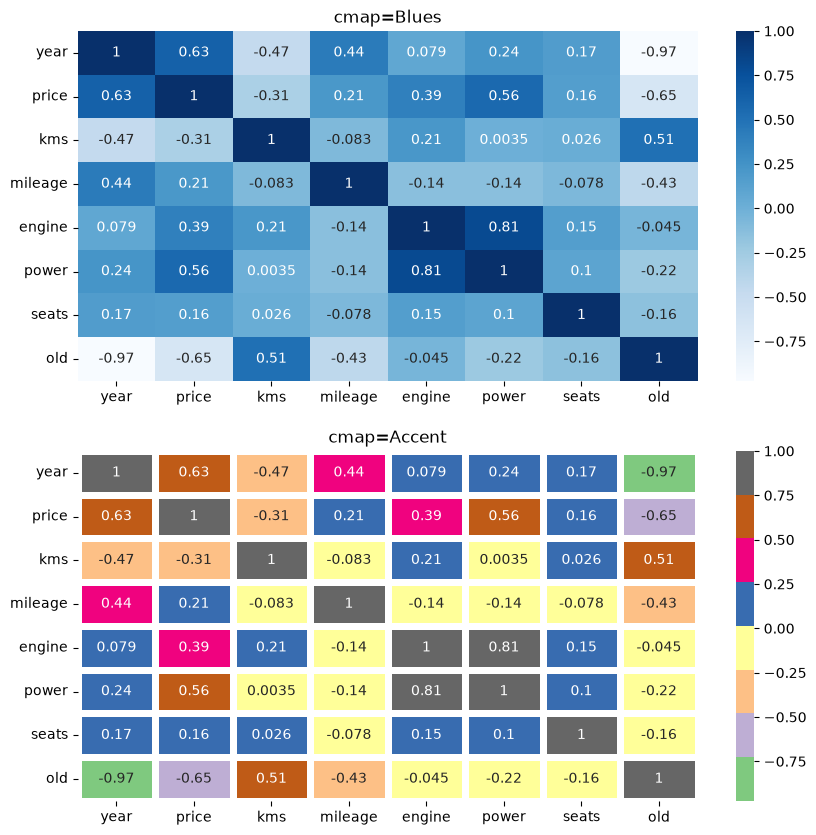

In [76]:
# plot variants of heatmaps using different parameters of sns.heatmap
fig,(ax1,ax2) = plt.subplots(nrows=2,figsize=(10,10))
sns.heatmap(train_corr,annot=True,ax=ax1,cmap="Blues")
sns.heatmap(train_corr,annot=True,ax=ax2,linewidth=5,cmap="Accent")
ax1.set_title("cmap=Blues")
ax2.set_title("cmap=Accent")

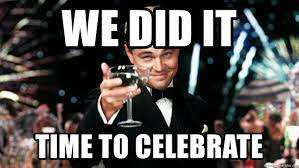

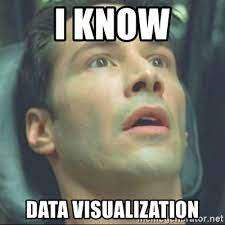

# Conclusion

EDA is a key to understand and represent your data in a better way which in result helps you
to build powerful and more generalized model.

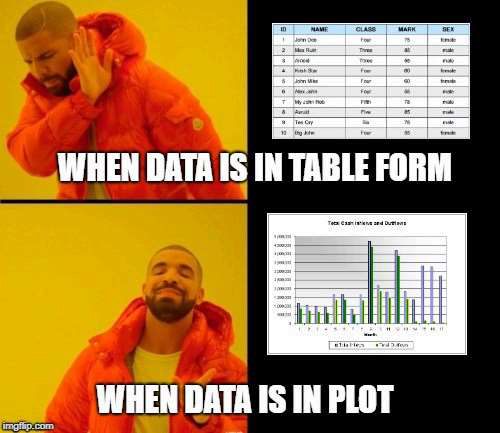

# A Big Congratulations!

You have done great work, now you're an analyst. Please fill the feedback form and let us
know where we can improve our service for you.

Friends, Next Get Ready to dive deeper into the field of Machine Learning, Glimpse of Future:

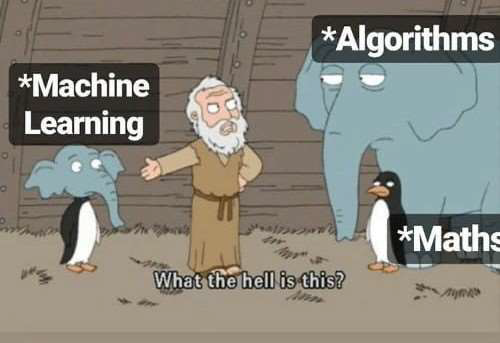